In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (12, 5)


In [4]:
DATA_PATH = '/Users/saloniagrawal/Desktop/Electricity_Demand_Forecasting /household_power_consumption.txt' # adjust path as needed

raw = pd.read_csv(DATA_PATH, sep=';', na_values='?', low_memory=False)
print("Raw shape:", raw.shape)
raw.head()


Raw shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
# Combine Date + Time into a proper datetime index
raw['datetime'] = pd.to_datetime(raw['Date'] + ' ' + raw['Time'], format='%d/%m/%Y %H:%M:%S')
raw = raw.drop(columns=['Date', 'Time']).set_index('datetime').sort_index()

for c in raw.columns:
    raw[c] = pd.to_numeric(raw[c], errors='coerce')

print("Date range:", raw.index.min(), "to", raw.index.max())
print("\nMissing values (%):")
print((raw.isna().mean() * 100).round(3))


Date range: 2006-12-16 17:24:00 to 2010-11-26 21:02:00

Missing values (%):
Global_active_power      1.252
Global_reactive_power    1.252
Voltage                  1.252
Global_intensity         1.252
Sub_metering_1           1.252
Sub_metering_2           1.252
Sub_metering_3           1.252
dtype: float64


In [6]:
daily = raw.resample('D').mean()
print("Daily shape:", daily.shape)
print("\nFully-missing days:", daily['Global_active_power'].isna().sum())

# Interpolate remaining gaps (time-based interpolation respects the calendar index)
daily = daily.interpolate(method='time')
print("Missing after interpolation:", daily.isna().sum().sum())

daily.head()


Daily shape: (1442, 7)

Fully-missing days: 9
Missing after interpolation: 0


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16,3.053475,0.088187,236.243763,13.082828,0.000000,1.378788,12.439394
2006-12-17,2.354486,0.156949,240.087028,9.999028,1.411806,2.907639,9.264583
2006-12-18,1.530435,0.112356,241.231694,6.421667,0.738194,1.820139,9.734722
2006-12-19,1.157079,0.104821,241.999313,4.926389,0.582639,5.279167,4.303472
2006-12-20,1.545658,0.111804,242.308062,6.467361,0.000000,1.838889,9.765972


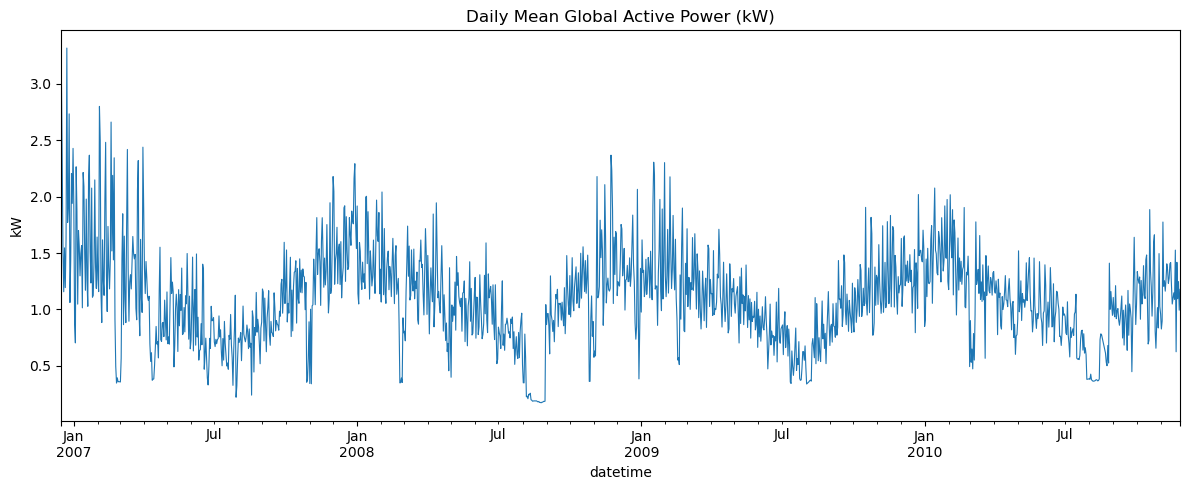

In [7]:
target = daily['Global_active_power'].copy()
target.name = 'GAP_daily'

fig, ax = plt.subplots()
target.plot(ax=ax, lw=0.8)
ax.set_title("Daily Mean Global Active Power (kW)")
ax.set_ylabel("kW")
plt.tight_layout()
plt.show()


In [8]:
HORIZON = 90
train = target.iloc[:-HORIZON]
test = target.iloc[-HORIZON:]
print(f"Train: {train.index.min()} -> {train.index.max()}  ({len(train)} days)")
print(f"Test : {test.index.min()} -> {test.index.max()}  ({len(test)} days)")


Train: 2006-12-16 00:00:00 -> 2010-08-28 00:00:00  (1352 days)
Test : 2010-08-29 00:00:00 -> 2010-11-26 00:00:00  (90 days)


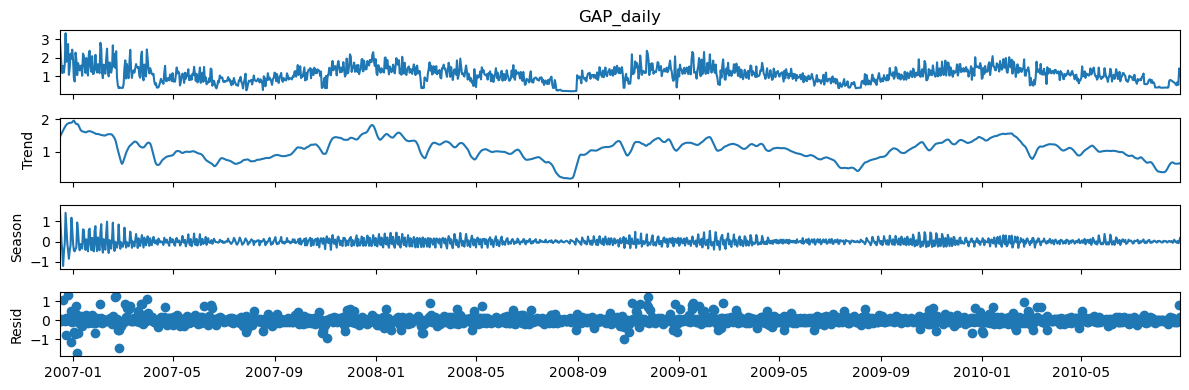

In [9]:
from statsmodels.tsa.seasonal import STL

stl = STL(train, period=7, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(12, 4)
plt.tight_layout()
plt.show()


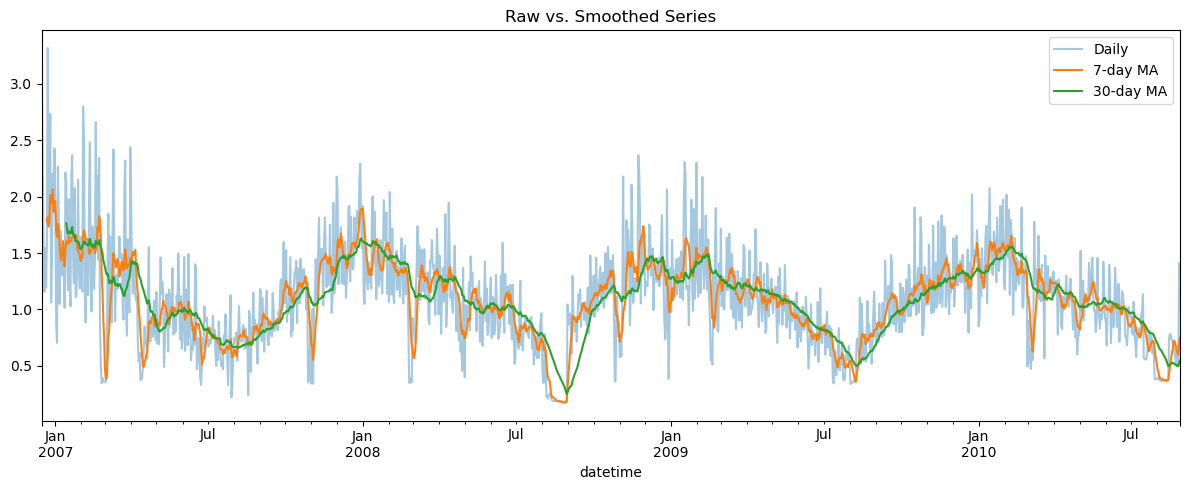

In [10]:
# 7-day and 30-day moving averages for visual smoothing comparison
fig, ax = plt.subplots()
train.plot(ax=ax, alpha=0.4, label='Daily')
train.rolling(7).mean().plot(ax=ax, label='7-day MA')
train.rolling(30).mean().plot(ax=ax, label='30-day MA')
ax.legend()
ax.set_title("Raw vs. Smoothed Series")
plt.tight_layout()
plt.show()


In [11]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf_test(series, name=""):
    stat, pvalue, usedlag, nobs, crit, icbest = adfuller(series.dropna(), autolag='AIC')
    print(f"--- ADF Test: {name} ---")
    print(f"Statistic: {stat:.4f}, p-value: {pvalue:.4f}, lags used: {usedlag}")
    print("Stationary" if pvalue < 0.05 else "Non-stationary", "(alpha=0.05)")
    print()

def kpss_test(series, name=""):
    stat, pvalue, lags, crit = kpss(series.dropna(), regression='c', nlags='auto')
    print(f"--- KPSS Test: {name} ---")
    print(f"Statistic: {stat:.4f}, p-value: {pvalue:.4f}, lags used: {lags}")
    print("Stationary" if pvalue > 0.05 else "Non-stationary", "(alpha=0.05)")
    print()

adf_test(train, "Original series")
kpss_test(train, "Original series")


--- ADF Test: Original series ---
Statistic: -3.4132, p-value: 0.0105, lags used: 22
Stationary (alpha=0.05)

--- KPSS Test: Original series ---
Statistic: 0.2633, p-value: 0.1000, lags used: 20
Stationary (alpha=0.05)



/var/folders/yc/r4597hp505j1r9sq_l5kc1hc0000gn/T/ipykernel_22596/3318706021.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, pvalue, lags, crit = kpss(series.dropna(), regression='c', nlags='auto')


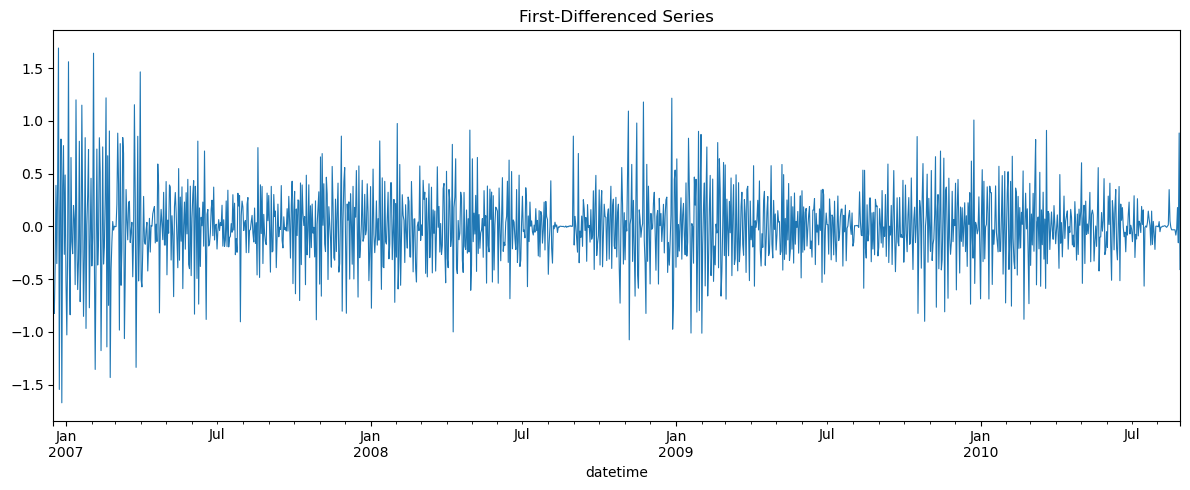

--- ADF Test: First difference (d=1) ---
Statistic: -12.8028, p-value: 0.0000, lags used: 19
Stationary (alpha=0.05)

--- KPSS Test: First difference (d=1) ---
Statistic: 0.0507, p-value: 0.1000, lags used: 11
Stationary (alpha=0.05)



/var/folders/yc/r4597hp505j1r9sq_l5kc1hc0000gn/T/ipykernel_22596/3318706021.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, pvalue, lags, crit = kpss(series.dropna(), regression='c', nlags='auto')


In [12]:
# First difference
train_diff1 = train.diff().dropna()

fig, ax = plt.subplots()
train_diff1.plot(ax=ax, lw=0.8)
ax.set_title("First-Differenced Series")
plt.tight_layout()
plt.show()

adf_test(train_diff1, "First difference (d=1)")
kpss_test(train_diff1, "First difference (d=1)")


In [13]:
# Seasonal difference (period=7) on top of regular differencing, if weekly seasonality persists
train_diff_seasonal = train_diff1.diff(7).dropna()

adf_test(train_diff_seasonal, "First + seasonal (lag-7) difference")
kpss_test(train_diff_seasonal, "First + seasonal (lag-7) difference")


--- ADF Test: First + seasonal (lag-7) difference ---
Statistic: -14.6207, p-value: 0.0000, lags used: 23
Stationary (alpha=0.05)

--- KPSS Test: First + seasonal (lag-7) difference ---
Statistic: 0.0195, p-value: 0.1000, lags used: 34
Stationary (alpha=0.05)



/var/folders/yc/r4597hp505j1r9sq_l5kc1hc0000gn/T/ipykernel_22596/3318706021.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, pvalue, lags, crit = kpss(series.dropna(), regression='c', nlags='auto')


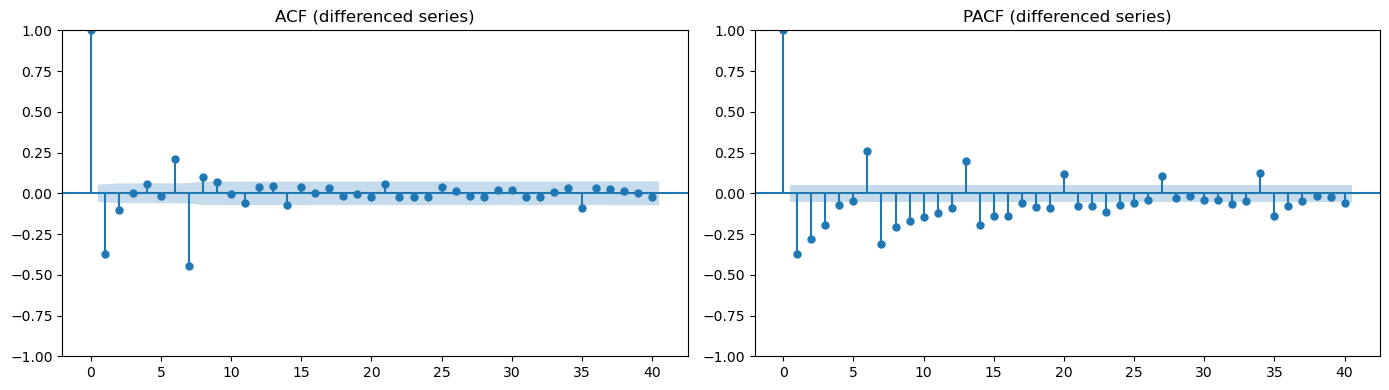

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train_diff_seasonal, lags=40, ax=axes[0])
plot_pacf(train_diff_seasonal, lags=40, ax=axes[1], method='ywm')
axes[0].set_title("ACF (differenced series)")
axes[1].set_title("PACF (differenced series)")
plt.tight_layout()
plt.show()


In [15]:
def eacf(z, ar_max=7, ma_max=7):
    """
    Extended ACF (Tsay & Tiao, 1984), adapted from the classic algorithm used in R's TSA::eacf.
    Returns a DataFrame of 'x' (significant) / 'o' (not significant) symbols.
    The top-left vertex of the largest all-'o' triangle suggests the (p, q) order.
    """
    z = np.asarray(z, dtype=float)
    n = len(z)
    symbol = np.full((ar_max + 1, ma_max + 1), 'x', dtype=object)

    # Build lagged design matrix once
    max_lag = ar_max + ma_max
    X_full = np.column_stack([np.roll(z, k)[max_lag:] for k in range(1, ar_max + 1)])
    y_full = z[max_lag:]

    for p in range(ar_max + 1):
        for q in range(ma_max + 1):
            k = p + q
            if k == 0:
                w = z.copy()
            else:
                X = np.column_stack([np.roll(z, i)[k:] for i in range(1, p + 1)]) if p > 0 else None
                y = z[k:]
                if p > 0:
                    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
                    resid = y - X @ beta
                    # Reconstruct filtered series w_t using AR(p) coefficients
                    w = np.concatenate([np.full(k, np.nan), resid])
                else:
                    w = z.copy()
            w = pd.Series(w).dropna().values
            if len(w) <= q + 5:
                symbol[p, q] = 'o'
                continue
            # significance of autocorrelation at lag (q+1) of the filtered series
            acf_vals = pd.Series(w).autocorr(lag=q + 1)
            se = 1 / np.sqrt(len(w))
            symbol[p, q] = 'o' if abs(acf_vals) < 1.96 * se else 'x'

    return pd.DataFrame(symbol,
                         index=[f"AR{p}" for p in range(ar_max + 1)],
                         columns=[f"MA{q}" for q in range(ma_max + 1)])

eacf_table = eacf(train_diff_seasonal.values, ar_max=6, ma_max=6)
eacf_table


,MA0,MA1,MA2,MA3,MA4,MA5,MA6
AR0,x,x,o,x,o,x,x
AR1,x,x,o,x,x,x,x
AR2,x,x,x,x,o,o,x
AR3,o,o,o,o,o,o,x
AR4,o,o,o,o,x,o,x
AR5,o,o,o,o,o,o,x
AR6,x,o,o,o,x,x,x


In [16]:
import itertools
import statsmodels.api as sm

candidates = []
p_range = range(0, 4)
q_range = range(0, 4)
P_range = range(0, 2)
Q_range = range(0, 2)
d, D, s = 1, 1, 7

for p, q, P, Q in itertools.product(p_range, q_range, P_range, Q_range):
    try:
        model = sm.tsa.statespace.SARIMAX(
            train, order=(p, d, q), seasonal_order=(P, D, Q, s),
            enforce_stationarity=False, enforce_invertibility=False
        )
        fit = model.fit(disp=False)
        candidates.append((p, d, q, P, D, Q, s, fit.aic, fit.bic))
    except Exception:
        continue

results_df = pd.DataFrame(candidates,
    columns=['p','d','q','P','D','Q','s','AIC','BIC']).sort_values('AIC')
results_df.head(10)


/Users/saloniagrawal/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/saloniagrawal/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/saloniagrawal/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/saloniagrawal/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/saloniagrawal/anaconda3/l

,p,d,q,P,D,Q,s,AIC,BIC
63,3,1,3,1,1,1,7,403.861157,450.617843
61,3,1,3,0,1,1,7,410.362591,451.924089
47,2,1,3,1,1,1,7,412.631866,454.193364
55,3,1,1,1,1,1,7,430.893822,467.265383
45,2,1,3,0,1,1,7,432.061159,468.427470
9,0,1,2,0,1,1,7,437.081948,457.865697
25,1,1,2,0,1,1,7,437.792715,463.772401
27,1,1,2,1,1,1,7,438.259259,469.434883
13,0,1,3,0,1,1,7,439.918466,465.894403
29,1,1,3,0,1,1,7,440.198381,471.369505


In [17]:
import pmdarima as pm

auto_model = pm.auto_arima(
    train, seasonal=True, m=7,
    start_p=0, start_q=0, max_p=4, max_q=4,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, trace=True,
    error_action='ignore', suppress_warnings=True, stepwise=True
)
print(auto_model.summary())


Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=1161.388, Time=0.06 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=906.644, Time=0.25 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=681.424, Time=0.37 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=1159.411, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[7] intercept   : AIC=715.968, Time=0.08 sec
 ARIMA(0,1,1)(1,0,1)[7] intercept   : AIC=534.100, Time=0.94 sec
 ARIMA(0,1,1)(1,0,0)[7] intercept   : AIC=670.795, Time=0.26 sec
 ARIMA(0,1,1)(2,0,1)[7] intercept   : AIC=536.278, Time=1.42 sec
 ARIMA(0,1,1)(1,0,2)[7] intercept   : AIC=536.067, Time=2.11 sec
 ARIMA(0,1,1)(0,0,2)[7] intercept   : AIC=663.321, Time=0.74 sec
 ARIMA(0,1,1)(2,0,0)[7] intercept   : AIC=640.288, Time=0.54 sec
 ARIMA(0,1,1)(2,0,2)[7] intercept   : AIC=538.051, Time=1.97 sec
 ARIMA(0,1,0)(1,0,1)[7] intercept   : AIC=962.753, Time=0.66 sec
 ARIMA(1,1,1)(1,0,1)[7] intercept   : AIC=520.021, Time=1.09 sec
 ARIMA(1,1,1)(0,0,1)[7] intercept   : AIC=619

In [18]:
# Fit the best model on the full training set (adjust order based on results_df / auto_model above)
best_order = (results_df.iloc[0][['p','d','q']]).astype(int).tolist()
best_seasonal_order = (results_df.iloc[0][['P','D','Q','s']]).astype(int).tolist()
print("Selected order:", best_order, "seasonal order:", best_seasonal_order)

sarima_model = sm.tsa.statespace.SARIMAX(
    train, order=tuple(best_order), seasonal_order=tuple(best_seasonal_order),
    enforce_stationarity=False, enforce_invertibility=False
)
sarima_fit = sarima_model.fit(disp=False)
print(sarima_fit.summary())


Selected order: [3, 1, 3] seasonal order: [1, 1, 1, 7]
                                      SARIMAX Results                                      
Dep. Variable:                           GAP_daily   No. Observations:                 1352
Model:             SARIMAX(3, 1, 3)x(1, 1, [1], 7)   Log Likelihood                -192.931
Date:                             Mon, 21 Sep 2026   AIC                            403.861
Time:                                     02:40:11   BIC                            450.618
Sample:                                 12-16-2006   HQIC                           421.383
                                      - 08-28-2010                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5122      0.047    -10.991      0.

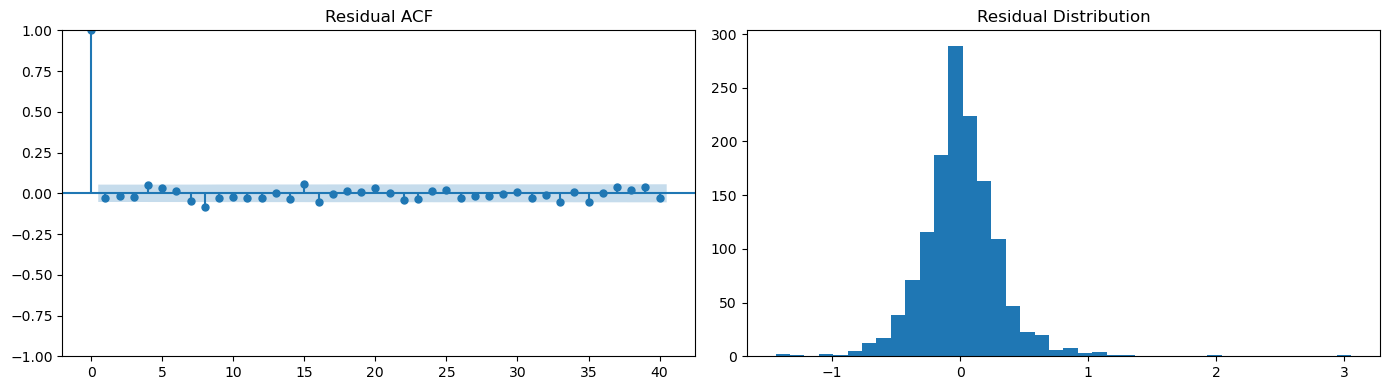

Ljung-Box test (H0: no autocorrelation up to lag k):
      lb_stat  lb_pvalue
10  20.931817   0.021574
20  35.674009   0.016795
30  42.585671   0.063705

Jarque-Bera stat: 5832.030, p-value: 0.0000, skew: 0.986, kurtosis: 12.982


In [19]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

resid = sarima_fit.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(resid, lags=40, ax=axes[0])
axes[0].set_title("Residual ACF")
axes[1].hist(resid, bins=40)
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(resid, lags=[10, 20, 30], return_df=True)
print("Ljung-Box test (H0: no autocorrelation up to lag k):")
print(lb)

jb_stat, jb_p, skew, kurt = jarque_bera(resid)
print(f"\nJarque-Bera stat: {jb_stat:.3f}, p-value: {jb_p:.4f}, skew: {skew:.3f}, kurtosis: {kurt:.3f}")


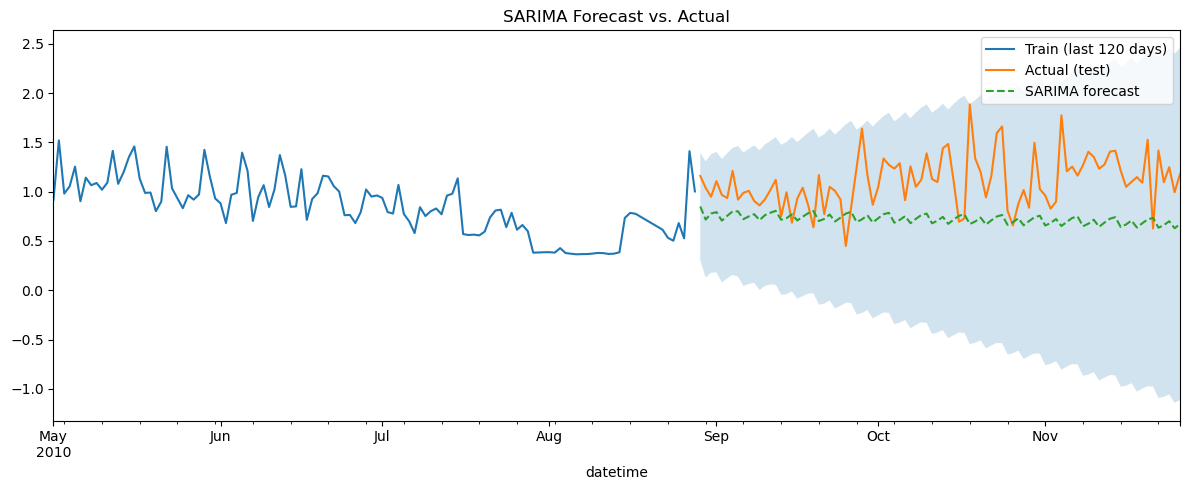

In [20]:
sarima_forecast = sarima_fit.get_forecast(steps=HORIZON)
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

fig, ax = plt.subplots()
train.iloc[-120:].plot(ax=ax, label='Train (last 120 days)')
test.plot(ax=ax, label='Actual (test)')
sarima_pred.plot(ax=ax, label='SARIMA forecast', style='--')
ax.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], alpha=0.2)
ax.legend()
ax.set_title("SARIMA Forecast vs. Actual")
plt.tight_layout()
plt.show()


In [21]:
def make_features(series, lags=(1,2,3,7,14,21,28), roll_windows=(7,14,30)):
    df_feat = pd.DataFrame({'y': series})
    for lag in lags:
        df_feat[f'lag_{lag}'] = series.shift(lag)
    for w in roll_windows:
        df_feat[f'roll_mean_{w}'] = series.shift(1).rolling(w).mean()
        df_feat[f'roll_std_{w}'] = series.shift(1).rolling(w).std()
    df_feat['dayofweek'] = df_feat.index.dayofweek
    df_feat['month'] = df_feat.index.month
    df_feat['is_weekend'] = (df_feat.index.dayofweek >= 5).astype(int)
    return df_feat.dropna()

full_feat = make_features(target)
train_feat = full_feat.loc[full_feat.index <= train.index[-1]]
test_feat = full_feat.loc[full_feat.index.isin(test.index)]

X_train, y_train = train_feat.drop(columns='y'), train_feat['y']
X_test, y_test = test_feat.drop(columns='y'), test_feat['y']
print(X_train.shape, X_test.shape)


(1322, 16) (90, 16)


In [22]:
from sklearn.model_selection import TimeSeriesSplit
import xgboost as xgb
import optuna

tscv = TimeSeriesSplit(n_splits=5)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    fold_rmse = []
    for tr_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        model = xgb.XGBRegressor(**params, objective='reg:squarederror', random_state=42)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        fold_rmse.append(np.sqrt(np.mean((y_val - pred) ** 2)))
    return np.mean(fold_rmse)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=40, show_progress_bar=True)
print("Best params:", study.best_params)
print("Best CV RMSE:", study.best_value)


[I 2026-09-21 02:40:12,326] A new study created in memory with name: no-name-57f5749c-a651-4b0b-a7a0-717640bb3e03
Best trial: 0. Best value: 0.271053:   2%|▏      | 1/40 [00:00<00:18,  2.13it/s]

[I 2026-09-21 02:40:12,821] Trial 0 finished with value: 0.27105251735335395 and parameters: {'n_estimators': 263, 'max_depth': 3, 'learning_rate': 0.009940984477642143, 'subsample': 0.7119844390270403, 'colsample_bytree': 0.7950046275093056, 'reg_alpha': 1.6598307768346676, 'reg_lambda': 0.0013591678113656237}. Best is trial 0 with value: 0.27105251735335395.


Best trial: 0. Best value: 0.271053:   5%|▎      | 2/40 [00:00<00:17,  2.19it/s]

[I 2026-09-21 02:40:13,267] Trial 1 finished with value: 0.30765059823099195 and parameters: {'n_estimators': 532, 'max_depth': 2, 'learning_rate': 0.2923875452240169, 'subsample': 0.8888113232250695, 'colsample_bytree': 0.8362765839082221, 'reg_alpha': 1.4088795997102768, 'reg_lambda': 0.014144062495703144}. Best is trial 0 with value: 0.27105251735335395.


Best trial: 0. Best value: 0.271053:   8%|▌      | 3/40 [00:02<00:29,  1.24it/s]

...

[I 2026-09-21 02:40:34,292] Trial 37 finished with value: 0.2733660550153394 and parameters: {'n_estimators': 484, 'max_depth': 4, 'learning_rate': 0.01011628774427518, 'subsample': 0.9225604693508624, 'colsample_bytree': 0.6933480186068868, 'reg_alpha': 0.7946797307006984, 'reg_lambda': 0.29842087702087255}. Best is trial 31 with value: 0.2653142239720016.


Best trial: 31. Best value: 0.265314:  98%|████▉| 39/40 [00:22<00:00,  1.43it/s]

[I 2026-09-21 02:40:34,949] Trial 38 finished with value: 0.2682292263833591 and parameters: {'n_estimators': 594, 'max_depth': 2, 'learning_rate': 0.006602474717968588, 'subsample': 0.8993222519184914, 'colsample_bytree': 0.8060796988692337, 'reg_alpha': 4.405454577334353, 'reg_lambda': 0.010587866954109522}. Best is trial 31 with value: 0.2653142239720016.


Best trial: 31. Best value: 0.265314: 100%|█████| 40/40 [00:23<00:00,  1.70it/s]

[I 2026-09-21 02:40:35,906] Trial 39 finished with value: 0.2813419930075861 and parameters: {'n_estimators': 521, 'max_depth': 4, 'learning_rate': 0.022908283741265082, 'subsample': 0.9595632960041952, 'colsample_bytree': 0.7762977103196608, 'reg_alpha': 1.0740547191321255, 'reg_lambda': 0.009269453923588125}. Best is trial 31 with value: 0.2653142239720016.
Best params: {'n_estimators': 546, 'max_depth': 2, 'learning_rate': 0.010854652438493975, 'subsample': 0.9167072769699002, 'colsample_bytree': 0.7945245636939856, 'reg_alpha': 3.2539855730629665, 'reg_lambda': 0.05035120962516919}
Best CV RMSE: 0.2653142239720016


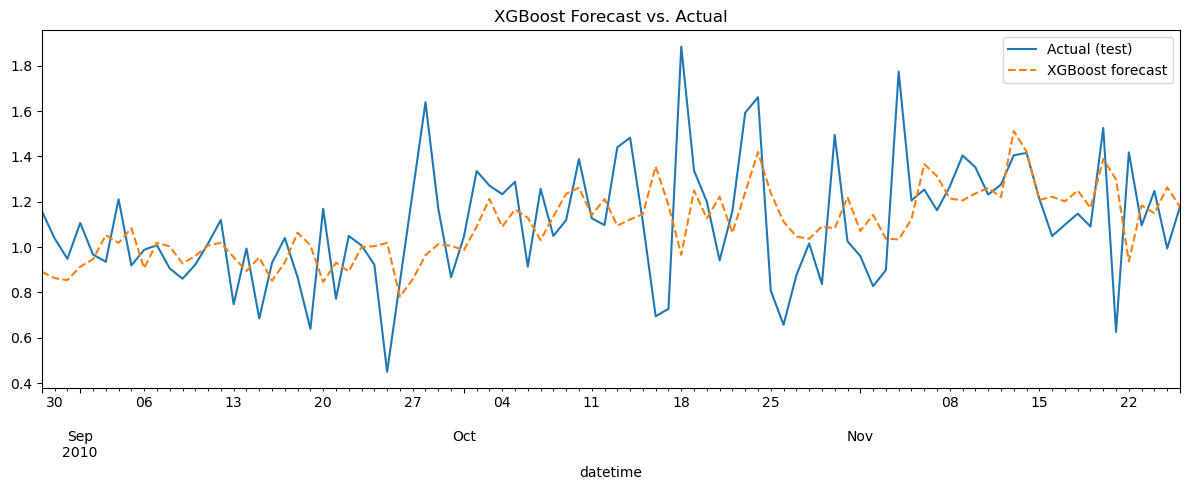

In [23]:
best_xgb = xgb.XGBRegressor(**study.best_params, objective='reg:squarederror', random_state=42)
best_xgb.fit(X_train, y_train)
xgb_pred = pd.Series(best_xgb.predict(X_test), index=X_test.index)

fig, ax = plt.subplots()
y_test.plot(ax=ax, label='Actual (test)')
xgb_pred.plot(ax=ax, label='XGBoost forecast', style='--')
ax.legend()
ax.set_title("XGBoost Forecast vs. Actual")
plt.tight_layout()
plt.show()


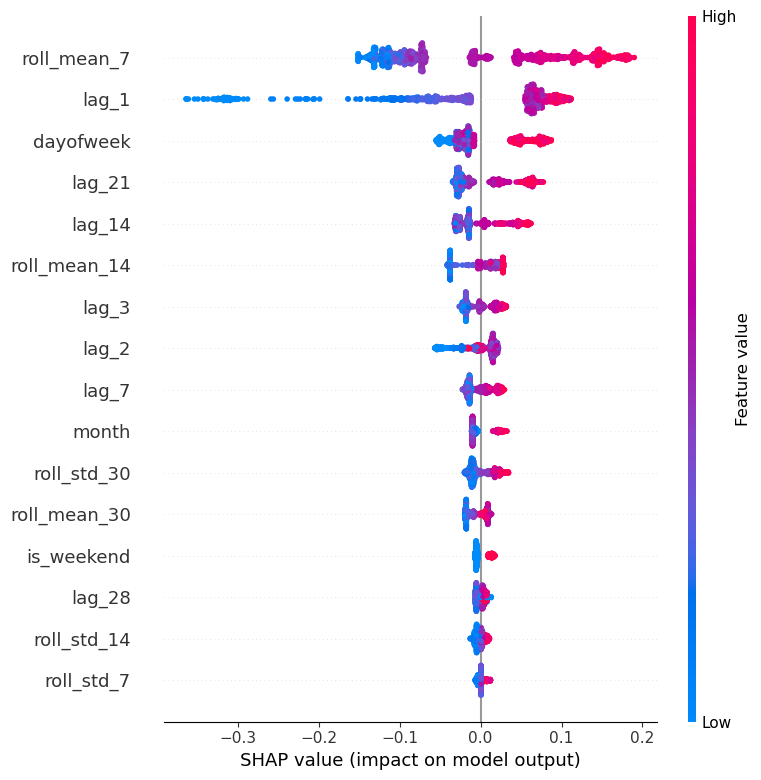

In [24]:
import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train, show=True)


In [25]:
def diebold_mariano(e1, e2, h=1):
    """
    Diebold-Mariano test comparing squared-error loss of two forecasts.
    H0: the two forecasts have equal accuracy.
    
    e1, e2 : arrays of forecast errors (actual - predicted) from Model 1 and Model 2
    h      : forecast horizon (used for the Newey-West-style variance correction)
    
    Returns: (DM statistic, p-value)
    """
    d = e1 ** 2 - e2 ** 2          # loss differential, using squared-error loss
    n = len(d)
    d_mean = d.mean()

    # Variance of d, with autocovariance correction for h > 1
    # (forecast errors at overlapping horizons are often autocorrelated)
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        cov = np.cov(d[:-lag], d[lag:])[0, 1]
        var_d += 2 * cov

    dm_stat = d_mean / np.sqrt(var_d / n)

    from scipy.stats import norm
    p_value = 2 * (1 - norm.cdf(abs(dm_stat)))
    return dm_stat, p_value

In [26]:
# Forecast errors — actual minus predicted, for each model
e_sarima = test.values - sarima_pred.values
e_xgb = y_test.values - xgb_pred.values

dm_stat, dm_pvalue = diebold_mariano(e_sarima, e_xgb)
print(f"DM statistic: {dm_stat:.3f}")
print(f"p-value: {dm_pvalue:.4f}")

if dm_pvalue < 0.05:
    print("The difference in forecast accuracy is statistically significant.")
else:
    print("No statistically significant difference between the two models' forecasts.")

DM statistic: 6.545
p-value: 0.0000
The difference in forecast accuracy is statistically significant.
